# Python Model Lab

## SET 1

### 1(a) Fibonacci Series
**Question:** A biologist models a species where each month's population equals the sum of the previous two months. Print the population for the first `n` months.

**Sample input:** `8`  
**Expected output:** `Population growth: 0 1 1 2 3 5 8 13`

In [ ]:
n = int(input("Enter number of months: "))
a, b = 0, 1
series = []

for _ in range(n):
    series.append(a)
    a, b = b, a + b

print("Population growth:", *series)

Enter number of months: 8
Population growth: 0 1 1 2 3 5 8 13


### 1(b) Multiplication Table
**Question:** Read a rate and print its multiplication table up to 10.

**Sample input:** `7`

In [ ]:
rate = int(input("Enter rate: "))

for i in range(1, 11):
    print(f"{rate} x {i} = {rate * i}")

Enter rate: 5
5 x 1 = 5
5 x 2 = 10
5 x 3 = 15
5 x 4 = 20
5 x 5 = 25
5 x 6 = 30
5 x 7 = 35
5 x 8 = 40
5 x 9 = 45
5 x 10 = 50


### 1(c) Largest of Three Numbers
**Question:** Read the monthly rent of three properties and display which property earns the most.

**Sample input:** `45000 52000 48500`

In [ ]:
r1, r2, r3 = map(int, input("Enter three rents: ").split())

if r1 >= r2 and r1 >= r3:
    print("Property 1 is highest:", r1)
elif r2 >= r1 and r2 >= r3:
    print("Property 2 is highest:", r2)
else:
    print("Property 3 is highest:", r3)

Enter three rents: 45000 44444 65455
Property 3 is highest: 65455


### 2(a) Data Loading and Inspection
**Question:** Load a transaction CSV, display the first rows, shape, data types, and missing-value counts.

In [ ]:
import pandas as pd
from io import StringIO

csv_data = StringIO("""CustomerID,Age,Amount,Category
C1,25,1200,Grocery
C2,,850,Fashion
C3,41,,Grocery
C4,35,15000,Electronics
C5,29,640,Fashion
""")

df = pd.read_csv(csv_data)
print(df.head())
print("Shape:", df.shape)
print(df.dtypes)
print("Missing values:")
print(df.isnull().sum())

  CustomerID   Age   Amount     Category
0         C1  25.0   1200.0      Grocery
1         C2   NaN    850.0      Fashion
2         C3  41.0      NaN      Grocery
3         C4  35.0  15000.0  Electronics
4         C5  29.0    640.0      Fashion
Shape: (5, 4)
CustomerID     object
Age           float64
Amount        float64
Category       object
dtype: object
Missing values:
CustomerID    0
Age           1
Amount        1
Category      0
dtype: int64


### 2(b) Missing-Value Imputation
**Question:** Fill missing `Age` with its column mean and missing `Amount` with its column median.

In [ ]:
import pandas as pd
from io import StringIO

df = pd.read_csv(StringIO("""CustomerID,Age,Amount,Category
C1,25,1200,Grocery
C2,,850,Fashion
C3,41,,Grocery
C4,35,15000,Electronics
C5,29,640,Fashion
"""))

df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Amount"] = df["Amount"].fillna(df["Amount"].median())
print(df)

  CustomerID   Age   Amount     Category
0         C1  25.0   1200.0      Grocery
1         C2  32.5    850.0      Fashion
2         C3  41.0   1025.0      Grocery
3         C4  35.0  15000.0  Electronics
4         C5  29.0    640.0      Fashion


### 2(c) Min-Max Scaling and Z-Score Standardization
**Question:** Scale `Amount` to 0–1 and standardize `Age` using the z-score formula.

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Age": [25, 32, 41, 35, 29],
    "Amount": [1200, 850, 1000, 15000, 640]
})

df["Amount_minmax"] = (
    (df["Amount"] - df["Amount"].min()) /
    (df["Amount"].max() - df["Amount"].min())
)
df["Age_zscore"] = (df["Age"] - df["Age"].mean()) / df["Age"].std()
print(df.round(3))

   Age  Amount  Amount_minmax  Age_zscore
0   25    1200          0.039      -1.220
1   32     850          0.015      -0.066
2   41    1000          0.025       1.418
3   35   15000          1.000       0.429
4   29     640          0.000      -0.560


### 2(d) Outlier Removal Using IQR
**Question:** Remove `Amount` values outside 1.5 times the interquartile range.

In [ ]:
import pandas as pd

df = pd.DataFrame({"Amount": [1200, 850, 1000, 15000, 640, 900]})
q1 = df["Amount"].quantile(0.25)
q3 = df["Amount"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

clean = df[(df["Amount"] >= low) & (df["Amount"] <= high)]
print("Bounds:", low, high)
print("Cleaned data:")
print(clean)

Bounds: 431.25 1581.25
Cleaned data:
   Amount
0    1200
1     850
2    1000
4     640
5     900


### 2(e) Data Visualization
**Question:** Plot total spending by category as a bar chart and monthly spending as a line chart.

Category
Electronics    6600
Fashion        1750
Grocery        2700
Name: Amount, dtype: int64


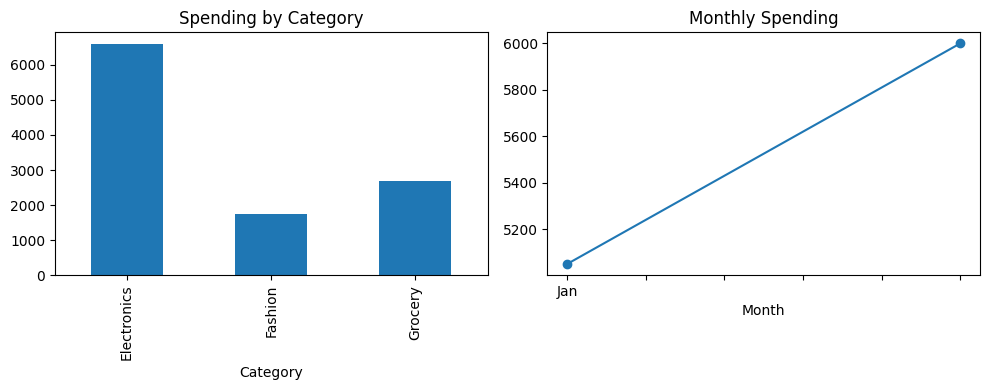

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Category": ["Grocery", "Fashion", "Electronics",
                 "Grocery", "Fashion", "Electronics"],
    "Month": ["Jan", "Jan", "Jan", "Feb", "Feb", "Feb"],
    "Amount": [1200, 850, 3000, 1500, 900, 3600]
})

totals = df.groupby("Category")["Amount"].sum()
monthly = df.groupby("Month", sort=False)["Amount"].sum()

print(totals)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
totals.plot(kind="bar", ax=ax[0], title="Spending by Category")
monthly.plot(kind="line", marker="o", ax=ax[1], title="Monthly Spending")
plt.tight_layout()
plt.show()

### 3(a) Block Matrix
**Question:** Combine four 2×2 matrices into one 4×4 composite matrix.

In [ ]:
import numpy as np

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
C = np.array([[9, 10], [11, 12]])
D = np.array([[13, 14], [15, 16]])

block = np.block([[A, B], [C, D]])
print(block)

[[ 1  2  5  6]
 [ 3  4  7  8]
 [ 9 10 13 14]
 [11 12 15 16]]


### 3(b) Reshape a Matrix and Cube Its Elements
**Question:** Reshape 12 sensor values into a 3×4 matrix and cube every element.

In [ ]:
import numpy as np

arr = np.arange(1, 13)
mat = arr.reshape(3, 4)
print("Reshaped matrix:")
print(mat)
print("Cube of elements:")
print(mat ** 3)

Reshaped matrix:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Cube of elements:
[[   1    8   27   64]
 [ 125  216  343  512]
 [ 729 1000 1331 1728]]


### 3(c) Row Sums and Column Sums
**Question:** Compute the sum of every row and every column in an expense matrix.

In [ ]:
import numpy as np

M = np.array([[10, 20, 30],
              [40, 50, 60],
              [70, 80, 90]])

print("Row sums:", M.sum(axis=1))
print("Column sums:", M.sum(axis=0))

Row sums: [ 60 150 240]
Column sums: [120 150 180]


## SET 2

### 1(a) Standard Normal Distribution and Z-Scores
**Question:** Generate standard normal variables and height data (mean 170 cm, standard deviation 8 cm). Convert heights to z-scores and verify mean ≈ 0 and standard deviation ≈ 1.

In [11]:
import numpy as np

z = np.random.randn(1000)

#height = mean + std * z
height = 170 + 8 * z

# Calculate z-scores
z_score = (height - 170) / 8
print("Mean:", np.mean(z_score))
print("Standard Deviation:", np.std(z_score))

Mean: 0.0358538765420999
Standard Deviation: 1.0169774976148278


### 1(b) Exponential Distribution
**Question:** Simulate customer waiting times with an average gap of 2 minutes and compare the simulated mean/probability with theoretical values.

In [8]:
import numpy as np

mean = 2
waiting_time = np.random.exponential(scale=mean, size=1000)
print("Average Waiting Time:", np.mean(waiting_time))

Average Waiting Time: 1.9513572474859988


### 1(c) Student's t Distribution
**Question:** For 10 degrees of freedom, estimate P(X > 2) and compare it with the standard normal tail probability.

In [12]:
import numpy as np
from scipy.stats import t, norm

df = 10

t_prob = t.sf(2, df)
normal_prob = norm.sf(2)

print("t-Distribution Probability:", t_prob)
print("Normal Distribution Probability:", normal_prob)

if t_prob > normal_prob:
    print("t-distribution has heavier tails")

t-Distribution Probability: 0.036694017385370196
Normal Distribution Probability: 0.022750131948179195
t-distribution has heavier tails


### 2(a) Prime Number Check Using a Function
**Question:** Define `is_prime(n)` and test the submitted PIN.

In [13]:
def is_prime(n):
    if n <= 1:
        return False
    for i in range(2, n):
        if n % i == 0:
            return False
    return True

# Test PIN
n = int(input("Enter PIN: "))

if is_prime(n):
    print("Prime Number")
else:
    print("Not a Prime Number")

Enter PIN: 55
Not a Prime Number



### 2(b) Perfect Number Check
**Question:** A number is perfect if the sum of its proper divisors equals the number.

In [15]:
n = int(input("Enter a number: "))
sum = 0
for i in range(1, n):
    if n % i == 0:
        sum += i

if sum == n:
    print("Perfect Number")
else:
    print("Not a Perfect Number")

Enter a number: 28
Perfect Number


### 2(c) Second-Largest Distinct Element
**Question:** Find the runner-up score from a list of candidate scores.

In [16]:
scores = [10, 20, 30, 40, 40, 30]

# Remove duplicates
scores = list(set(scores))

# Sort scores
scores.sort()

# Find runner-up
print("Runner-up Score:", scores[-2])

Runner-up Score: 30


### 3(a) Matrix Rank and Linear Dependence
**Question:** Find the rank of a matrix and determine whether its rows are linearly dependent.

In [17]:
import numpy as np

A = np.array([[1, 2, 3],
              [2, 4, 6],
              [1, 1, 1]])

rank = np.linalg.matrix_rank(A)

print("Rank:", rank)

if rank < A.shape[0]:
    print("Rows are linearly dependent")
else:
    print("Rows are linearly independent")

Rank: 2
Rows are linearly dependent


### 3(b) Non-Commutativity of Matrix Multiplication
**Question:** Show that A×B is not equal to B×A.

In [21]:
import numpy as np

A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])

print("AB =\n",A @ B)
print("BA =\n",B @ A)
print("Equal?", np.array_equal(A @ B, B @ A))

AB =
 [[2 1]
 [4 3]]
BA =
 [[3 4]
 [1 2]]
Equal? False


### 3(c) Block Diagonal Matrix and Determinant
**Question:** Build a block diagonal matrix from two 2×2 matrices and verify the determinant product property.

In [23]:
import numpy as np
from scipy.linalg import block_diag

A = np.array([[1, 2],[3, 4]])
B = np.array([[2, 0],[0, 3]])

# Create block diagonal matrix
C = block_diag(A, B)

# Calculate determinants
det_A = np.linalg.det(A)
det_B = np.linalg.det(B)
det_C = np.linalg.det(C)

print("Block Matrix:\n", C)
print("Determinant of A:", det_A)
print("Determinant of B:", det_B)
print("Determinant of C:", det_C)

print("Product of determinants:", det_A * det_B)

Block Matrix:
 [[1 2 0 0]
 [3 4 0 0]
 [0 0 2 0]
 [0 0 0 3]]
Determinant of A: -2.0000000000000004
Determinant of B: 6.0
Determinant of C: -12.000000000000005
Product of determinants: -12.000000000000004


## SET 3

### 1(a) Filter Words That Contain a Digit
**Question:** Extract every word in a message that contains at least one digit.

In [27]:
text = input("Enter a sentence: ")

words = text.split()

for word in words:
    if any(ch.isdigit() for ch in word):
        print(word)

Enter a sentence: FCB Leo10
Leo10


### 1(b) Uppercase Vowels and Lowercase Consonants
**Question:** Convert vowels to uppercase and all other characters to lowercase.

In [ ]:
text = input("Enter text: ")
out = ""

for ch in text:
    if ch.lower() in "aeiou":
        out += ch.upper()
    else:
        out += ch.lower()

print(out)

Enter text:  tech team forms
 tEch tEAm fOrms


### 1(c) First-and-Last-Letter Abbreviation
**Question:** For each word in a multi-word title, take its first and last letter and combine them.

In [ ]:
title = input("Enter project title: ").split()
abbr = "".join(w[0] + w[-1] for w in title).upper()
print("Abbreviation:", abbr)

In [1]:
title = input("Enter project title: ")

words = title.split()

acronym = ""

for word in words:
    acronym += word[0].upper() + word[-1].upper()

print("Acronym:", acronym)

Enter project title: fcb
Acronym: FB


### 2(a) Matrix Slicing
**Question:** Extract the central 2×2 region and the last column from a 4×4 matrix.

In [3]:
import numpy as np

img = np.arange(1, 17).reshape(4, 4)
print("Image:")
print(img)
print("Central 2x2 region:")
print(img[1:3, 1:3])
print("Last column:", img[:, -1])

Image:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
Central 2x2 region:
[[ 6  7]
 [10 11]]
Last column: [ 4  8 12 16]


### 2(b) Matrix Multiplication
**Question:** Multiply A (2×3) by B (3×2).

In [4]:
import numpy as np

A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[7, 8], [9, 10], [11, 12]])

print("A x B =")
print(A@B)

A x B =
[[ 58  64]
 [139 154]]


### 2(c) Random Matrix Multiplication
**Question:** Generate two random 2×2 integer matrices using seed 7 and multiply them.

In [5]:
import numpy as np

np.random.seed(7)
X = np.random.randint(0, 5, size=(2, 2))
Y = np.random.randint(0, 5, size=(2, 2))

print("X =", X.tolist())
print("Y =", Y.tolist())
print("X @ Y =")
print(X @ Y)

X = [[4, 1], [3, 3]]
Y = [[4, 1], [0, 1]]
X @ Y =
[[16  5]
 [12  6]]


### 3(a) Count Words Longer Than Six Characters
**Question:** Count words with more than six characters in a paragraph.

In [ ]:
words = input("Enter a paragraph: ").split()
print("Long words:", sum(1 for w in words if len(w) > 6))

### 3(b) Count Tokens with Repeated Digits
**Question:** Count identification tokens containing at least one repeated digit.

In [7]:
tokens = input("Enter tokens separated by spaces: ").split()
count = sum(1 for token in tokens if len(set(token)) < len(token))
print("Tokens with repeated digits:", count)

Enter tokens separated by spaces: 55573
Tokens with repeated digits: 1


### 3(c) Generate Pythagorean Triples
**Question:** List all integer right-angle triples `(a, b, c)` with a < b < c and c up to a given limit.

In [8]:
limit = int(input("Enter upper limit: "))

for a in range(1, limit + 1):
    for b in range(a + 1, limit + 1):
        c = (a * a + b * b) ** 0.5
        if c == int(c) and c <= limit:
            print((a, b, int(c)))

Enter upper limit: 67
(3, 4, 5)
(5, 12, 13)
(6, 8, 10)
(7, 24, 25)
(8, 15, 17)
(9, 12, 15)
(9, 40, 41)
(10, 24, 26)
(11, 60, 61)
(12, 16, 20)
(12, 35, 37)
(14, 48, 50)
(15, 20, 25)
(15, 36, 39)
(16, 30, 34)
(16, 63, 65)
(18, 24, 30)
(20, 21, 29)
(20, 48, 52)
(21, 28, 35)
(24, 32, 40)
(24, 45, 51)
(25, 60, 65)
(27, 36, 45)
(28, 45, 53)
(30, 40, 50)
(33, 44, 55)
(33, 56, 65)
(36, 48, 60)
(39, 52, 65)
(40, 42, 58)


## SET 4

### 1(a) Fibonacci Numbers Less Than n
**Question:** Print all Fibonacci numbers strictly below a threshold.

In [9]:
n = int(input("Enter threshold: "))
a, b = 0, 1
result = []

while a < n:
    result.append(a)
    a, b = b, a + b

print("Milestones below", n, ":", *result)

Enter threshold: 3
Milestones below 3 : 0 1 1 2


### 1(b) Armstrong Numbers in a Range
**Question:** List every Armstrong number between the lower and upper limits, inclusive.

In [12]:
low, high = map(int, input("Enter lower and upper limits: ").split())
found = []

for num in range(low, high + 1):
    digits = str(num)
    if sum(int(d) ** len(digits) for d in digits) == num:
        found.append(num)

print("Armstrong numbers:", found)

Enter lower and upper limits: 12  555
Armstrong numbers: [153, 370, 371, 407]


### 1(c) Merge Two Lists Without Duplicates
**Question:** Combine two mailing lists, preserving first-appearance order.

In [20]:
list1 = (input("Enter first list: ").split())

list2 = (input("Enter second list: ").split())

merged = list1[:]
for item in list2:
    if item not in merged:
        merged.append(item)

print("Merged list:", merged)

Enter first list: 44 55 
Enter second list: 83 9
Merged list: ['44', '55', '83', '9']


### 2(a) Random Matrix, Sums, and Squares
**Question:** Generate a random 3×3 integer matrix (seed 42) and print its total sum, row sums, and squared elements.

In [30]:
import numpy as np

np.random.seed(2)
R = np.random.randint(1, 10, size=(3, 3))

print("Matrix:")
print(R)
print("Total sum:", R.sum())
print("Row sums:", R.sum(axis=1))
print("Squares:")
print(R ** 2)

Matrix:
[[9 9 7]
 [3 9 8]
 [3 2 6]]
Total sum: 56
Row sums: [25 20 11]
Squares:
[[81 81 49]
 [ 9 81 64]
 [ 9  4 36]]


### 2(b) Block Matrix Using Identity and Zero Matrices
**Question:** Construct a 4×4 block matrix with I in the top-left, zero matrices in the off-diagonal blocks, and 2I in the bottom-right.

In [28]:
import numpy as np

I = np.eye(2, dtype=int)
Z = np.zeros((2, 2), dtype=int)
block = np.block([[I, Z], [Z, 2 * I]])
print(block)

[[1 0 0 0]
 [0 1 0 0]
 [0 0 2 0]
 [0 0 0 2]]


### 2(c) Square and Cube of Matrix Elements
**Question:** Compute the element-wise square and cube of a matrix.

In [ ]:
import numpy as np

A = np.array([[1, 2], [3, 4]])
print("Square:")
print(A ** 2)
print("Cube:")
print(A ** 3)

### 3(a) Poisson Distribution
**Question:** Simulate hourly customer arrivals for a Poisson distribution with λ = 4. Estimate P(X > 6) and compare with the exact value.

In [ ]:
import numpy as np
from scipy.stats import poisson

np.random.seed(3)
n = int(input("Number of simulations: "))
arrivals = np.random.poisson(lam=4, size=n)

print("Average arrivals per hour:", round(arrivals.mean(), 3))
print("P(X > 6) simulated:", round(np.mean(arrivals > 6), 4))
print("P(X > 6) exact:", round(1 - poisson.cdf(6, 4), 4))

### 3(b) Binomial Distribution
**Question:** Simulate 10 fair coin tosses per experiment, repeat the experiment, and find the most frequent number of heads.

In [32]:
import numpy as np

np.random.seed(0)
experiments = int(input("Number of experiments: "))
heads = np.random.binomial(n=10, p=0.5, size=experiments)
counts = np.bincount(heads, minlength=11)

for h, count in enumerate(counts):
    print(f"{h:2d} heads: {count}")

print("Most frequent number of heads:", counts.argmax())

KeyboardInterrupt: Interrupted by user

### 3(c) Beta Distribution
**Question:** Generate samples from Beta(2, 5) and compute the expected probability.

In [ ]:
import numpy as np

np.random.seed(19)
n = int(input("Number of samples: "))
a, b = 2, 5
p = np.random.beta(a, b, n)

print("Theoretical expected probability:", round(a / (a + b), 4))
print("Simulated expected probability:", round(p.mean(), 4))
print("Range: min =", round(p.min(), 3),
      "max =", round(p.max(), 3))

## SET 5

### 1(a–c) Image Matrix Slicing, Reshaping, Cubing, and Block Matrix
**Question:** Extract rows 1–2 and columns 1–2 from a 4×4 image matrix; reshape 9 pixels into 3×3 and cube them; construct a 4×4 block matrix using identity, zero, and two constant matrices.

In [33]:
import numpy as np

# (a) Matrix slicing (Python indexing starts at 0)
image_patch = np.array([
    [10, 20, 30, 40],
    [50, 60, 70, 80],
    [90, 100, 110, 120],
    [130, 140, 150, 160]
])
sub_region = image_patch[1:3, 1:3]
print("(a) Extracted 2x2 Sub-Region:\n", sub_region)

# (b) Reshape and cube
pixel_stream = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
reshaped_patch = pixel_stream.reshape(3, 3)
cubed_patch = reshaped_patch ** 3
print("\n(b) Reshaped 3x3 Matrix:\n", reshaped_patch)
print("Cubed Patch:\n", cubed_patch)

# (c) Block matrix
I = np.eye(2, dtype=int)
Z = np.zeros((2, 2), dtype=int)
A = np.full((2, 2), 5)
print(A)
B = np.full((2, 2), 9)
block_matrix = np.block([[I, Z], [A, B]])
print("\n(c) 4x4 Composite Block Matrix:\n", block_matrix)

(a) Extracted 2x2 Sub-Region:
 [[ 60  70]
 [100 110]]

(b) Reshaped 3x3 Matrix:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
Cubed Patch:
 [[  1   8  27]
 [ 64 125 216]
 [343 512 729]]
[[5 5]
 [5 5]]

(c) 4x4 Composite Block Matrix:
 [[1 0 0 0]
 [0 1 0 0]
 [5 5 9 9]
 [5 5 9 9]]


### 2(a–b) Longest Strictly Increasing Period and Circular String Rotation
**Question:** Find the length of the longest continuous strictly increasing run in temperature readings. Determine whether one device code is a circular rotation of another.

In [34]:
def longest_increasing_sublist(arr):
    if not arr:
        return 0

    max_len = 1
    curr_len = 1

    for i in range(1, len(arr)):
        if arr[i] > arr[i - 1]:
            curr_len += 1
            max_len = max(max_len, curr_len)
        else:
            curr_len = 1

    return max_len


def is_rotation(s1, s2):
    if len(s1) != len(s2) or not s1:
        return False
    return s2 in (s1 + s1)


readings = [12, 15, 18, 14, 16, 20, 22, 19]
print("(a) Longest Increasing Sublist Length:",
      longest_increasing_sublist(readings))

token1 = "ABCD"
token2 = "CDAB"
print("(b) Is Rotation:", is_rotation(token1, token2))

(a) Longest Increasing Sublist Length: 4
(b) Is Rotation: True


### 3(a–b) Generator-Based Sensor Normalization and NumPy Broadcasting
**Question:** Generate 1,000 sensor readings lazily, standardize using the sample mean and standard deviation, and use broadcasting to calculate spare-part bills and find the highest-revenue workgroup.

In [ ]:
import numpy as np

# (a) Lazy generation and normalization
data = np.fromiter((np.random.rand() for _ in range(1000)), dtype=float)
mean = np.mean(data)
std = np.std(data, ddof=1)  # sample standard deviation
normalized = (data - mean) / std

print("--- (a) Sensor Normalization ---")
print("Original Mean =", mean)
print("Original Sample Standard Deviation =", std)
print("First five normalized values =", normalized[:5])
print("Normalized Mean =", np.mean(normalized))
print("Normalized Sample Standard Deviation =", np.std(normalized, ddof=1))
print("Is mean close to 0?:", np.isclose(np.mean(normalized), 0))

# (b) Broadcasting - spare-part billing
S = np.array([
    [320, 360, 400],
    [280, 310, 350],
    [450, 480, 520],
    [240, 270, 300]
])
d = np.array([20, 25, 30])
t = np.array([[0.05], [0.08], [0.10], [0.06]])

final = (S - d) * (1 + t)
revenue = final.sum(axis=1)
best = np.argmax(revenue)

print("\n--- (b) Robot Spare-Part Billing ---")
print("Final Bill Matrix Shape:", final.shape)
print("Final Bill Matrix:\n", final)
print("Revenue by Group:", revenue)
print("Maximum Revenue Group:", best + 1)

## SET 6

### 1(a–c) List Operations on Student Marks
**Question:** Remove duplicate scores and sort ascending; remove the lowest and highest marks and reverse the remaining entry order; copy the original list and sort the copy descending without changing the original.

In [ ]:
# (a) Remove duplicates and sort ascending
raw_scores = [75, 42, 88, 75, 60, 42, 95, 88]
unique_sorted_scores = sorted(set(raw_scores))
print("--- (a) Unique Scores (Ascending) ---")
print("Original Scores:", raw_scores)
print("Processed Scores:", unique_sorted_scores)

# (b) Remove minimum and maximum, then reverse
marks = [55, 12, 98, 45, 82, 67]
print("\n--- (b) Trim Extremes and Reverse ---")
print("Original Marks:", marks)
marks.remove(min(marks))
marks.remove(max(marks))
marks.reverse()
print("Remaining Marks (Reversed):", marks)

# (c) Copy and sort descending
base_marks = [68, 92, 45, 85, 77]
merit_list = base_marks.copy()
merit_list.sort(reverse=True)
print("\n--- (c) Copy and Sort Descending ---")
print("Original List (Unchanged):", base_marks)
print("Merit List (Descending):", merit_list)

### 2(a–c) Line, Scatter, Vertical Bar, and Horizontal Bar Plots
**Question:** Generate 100 random integer stress readings (1–100). Plot the same readings as a line plot, scatter plot, vertical bar chart, and horizontal bar chart.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
measurements = np.random.randint(1, 101, size=100)
sample_index = np.arange(1, 101)

# (a) Line plot
plt.figure(figsize=(7, 4))
plt.plot(sample_index, measurements, label="Component Stress")
plt.title("Line Plot of 100 Stress Readings")
plt.xlabel("Sample Index")
plt.ylabel("Stress Value")
plt.legend()
plt.show()

# (b) Scatter plot
plt.figure(figsize=(7, 4))
plt.scatter(sample_index, measurements, label="Inspection Data")
plt.title("Scatter Plot of 100 Stress Readings")
plt.xlabel("Sample Index")
plt.ylabel("Stress Value")
plt.legend()
plt.show()

# (c1) Vertical bar plot
plt.figure(figsize=(7, 4))
plt.bar(sample_index, measurements, label="Readings")
plt.title("Vertical Bar Plot of 100 Random Readings")
plt.xlabel("Sample Index")
plt.ylabel("Value")
plt.legend()
plt.show()

# (c2) Horizontal bar plot
plt.figure(figsize=(7, 4))
plt.barh(sample_index, measurements, label="Readings")
plt.title("Horizontal Bar Plot of 100 Random Readings")
plt.xlabel("Value")
plt.ylabel("Sample Index")
plt.legend()
plt.show()

### 3(a–c) Dictionary Sales Analysis
**Question:** Find total sales across four smartphone brands, filter brands with more than 50 sales using dictionary comprehension, and identify the top-selling brand.

In [36]:
brand_sales = {
    "Samsung": 45,
    "Apple": 82,
    "OnePlus": 95,
    "Xiaomi": 38
}

print("--- Initial Brand Sales Data ---")
print(brand_sales)

# (a) Total sales
total_units = sum(brand_sales.values())
print("\n(a) Total sales units:", total_units)

# (b) Dictionary comprehension
high_performing = {
    brand: sales
    for brand, sales in brand_sales.items()
    if sales > 50
}
print("\n(b) Brands with sales greater than 50:", high_performing)

# (c) Maximum sales brand
top_brand = max(brand_sales, key=brand_sales.get)
print("\n(c) Top-selling brand:",
      top_brand, "(Units:", brand_sales[top_brand], ")")

--- Initial Brand Sales Data ---
{'Samsung': 45, 'Apple': 82, 'OnePlus': 95, 'Xiaomi': 38}

(a) Total sales units: 260

(b) Brands with sales greater than 50: {'Apple': 82, 'OnePlus': 95}

(c) Top-selling brand: OnePlus (Units: 95 )


## SET 7

### 1(a–c) Student Marks: Average, Maximum, and Even Marks
**Question:** Accept a list of marks, compute the average, define a function returning the highest mark, and count even numerical marks.

In [ ]:
marks = list(map(float, input("Enter marks separated by spaces: ").split()))

# (a) Average
average = sum(marks) / len(marks)
print("Average Marks:", round(average, 2))

# (b) User-defined function
def max_element(lst):
    return max(lst)

print("Maximum Score:", max_element(marks))

# (c) Count even marks
even_count = sum(1 for m in marks if int(m) % 2 == 0)
print("Count of Even Marks:", even_count)

### 2(a–c) Monte Carlo π, Sliding Windows/Covariance, and Lazy Random Data
**Question:** Generate 10,000 random coordinate pairs and estimate π using a quarter circle; create length-10 sliding windows from 200 observations and compute covariance; lazily generate 500 random values and calculate mean, variance, and median.

In [37]:
import numpy as np

# (a) Monte Carlo estimation of pi
N = 10000
points = ((np.random.rand(), np.random.rand()) for _ in range(N))
inside = sum(1 for x, y in points if x*x + y*y <= 1)
pi_est = 4 * inside / N
print("--- (a) Monte-Carlo Estimation of Pi ---")
print("Total Points Inside Quarter Circle:", inside)
print("Estimated Pi:", pi_est)

# (b) Sliding windows and covariance
data_stream = np.random.rand(200)
windows = (data_stream[i:i + 10] for i in range(len(data_stream) - 9))
covariances = [np.cov(w) for w in windows]
print("\n--- (b) Sliding Windows and Covariance ---")
print("Total Windows Evaluated:", len(covariances))
print("First 3 Window Covariances:", covariances[:3])

# (c) Lazy generation using np.fromiter
random_vals = np.fromiter((np.random.rand() for _ in range(500)), dtype=float)
print("\n--- (c) Statistics of 500 Random Values ---")
print("Mean:", np.mean(random_vals))
print("Variance:", np.var(random_vals))
print("Median:", np.median(random_vals))

--- (a) Monte-Carlo Estimation of Pi ---
Total Points Inside Quarter Circle: 7888
Estimated Pi: 3.1552

--- (b) Sliding Windows and Covariance ---
Total Windows Evaluated: 191
First 3 Window Covariances: [array(0.118481), array(0.11893089), array(0.0756476)]

--- (c) Statistics of 500 Random Values ---
Mean: 0.5040982108023009
Variance: 0.08702020036554266
Median: 0.514804921711645


### 3(a–c) List Comprehensions for Text Processing
**Question:** Keep purely alphabetic tokens and lowercase them; reverse words longer than four characters; create first-and-last-letter abbreviations for words with at least two characters.

In [ ]:
# (a) Alphabetic words in lowercase
tokens = ["DataScience", "AI#2026", "Machine", "NLP!", "analytics", "100x"]
clean_words = [t.lower() for t in tokens if t.isalpha()]
print("(a) Alphabetic Words in Lowercase:", clean_words)

# (b) Reverse words longer than four characters
sentence = "cloud systems deliver high performance output"
reversed_words = [w[::-1] for w in sentence.split() if len(w) > 4]
print("(b) Reversed Words (> 4 chars):", reversed_words)

# (c) First-and-last-letter abbreviations
tags = ["router", "ip", "s", "gateway", "switch"]
abbreviations = [w[0] + w[-1] for w in tags if len(w) >= 2]
print("(c) Two-Letter Abbreviations:", abbreviations)

## SET 8

### 1(a–c) Matplotlib: Multiple Line, Pie, and Bar Charts
**Question:** Plot two hiring series across five academic years; create a student budget pie chart; create a bar chart of company visits by department.

In [ ]:
import matplotlib.pyplot as plt

# (a) Multiple line plot
years = [1, 2, 3, 4, 5]
series_1 = [40, 48, 55, 62, 70]
series_2 = [35, 42, 45, 50, 58]

plt.figure(figsize=(6, 4))
plt.plot(years, series_1, marker="o", label="Domain A (Series 1)")
plt.plot(years, series_2, marker="s", label="Domain B (Series 2)")
plt.title("Annual Campus Hiring Comparison")
plt.xlabel("Academic Year")
plt.ylabel("Placed Students")
plt.legend()
plt.grid(True)
plt.show()

# (b) Pie chart
expenditures = ["Tuition", "Rent", "Food", "Books"]
proportions = [45, 25, 18, 12]

plt.figure(figsize=(5, 5))
plt.pie(proportions, labels=expenditures,
        autopct="%1.1f%%", startangle=140)
plt.title("Student Expense Allocation")
plt.show()

# (c) Bar chart
depts = ["A", "B", "C", "D", "E"]
company_visits = [18, 32, 24, 28, 15]

plt.figure(figsize=(6, 4))
plt.bar(depts, company_visits)
plt.title("Recruiting Companies by Department")
plt.xlabel("Department")
plt.ylabel("Number of Visits")
plt.show()

### 2(a) Elements Appearing More Than n/3 Times
**Question:** Identify all distinct voter IDs that appear strictly more than n/3 times.

In [ ]:
def elements_more_than_n_by_3(votes):
    n = len(votes)
    freq = {}

    for vote in votes:
        freq[vote] = freq.get(vote, 0) + 1

    result = [item for item, count in freq.items() if count > n / 3]
    return result


voter_ids = [1, 2, 3, 1, 1, 2, 1, 4]
print("Voter IDs with > n/3 votes:",
      elements_more_than_n_by_3(voter_ids))

### 2(b) Maximum Product of Any Three Numbers
**Question:** Find the maximum product obtainable by choosing any three values from a list that may contain positive and negative numbers.

**Note:** The two smallest (possibly negative) values multiplied by the largest value can beat the product of the three largest values.

In [ ]:
def max_product_of_three(nums):
    if len(nums) < 3:
        raise ValueError("At least three numbers are required")

    nums = sorted(nums)
    prod1 = nums[-1] * nums[-2] * nums[-3]
    prod2 = nums[0] * nums[1] * nums[-1]
    return max(prod1, prod2)


scores = [-10, -10, 5, 2, 8]
print("Maximum product of three numbers:",
      max_product_of_three(scores))

### 3(a) Eigenvalues, Eigenvectors, and Orthogonality
**Question:** For a symmetric stiffness matrix, compute eigenvalues/eigenvectors and verify that eigenvectors for distinct modes are orthogonal.

In [ ]:
import numpy as np

K = np.array([
    [3.0, 1.0],
    [1.0, 3.0]
])

vals, vecs = np.linalg.eig(K)
v1 = vecs[:, 0]
v2 = vecs[:, 1]
ortho_dot = np.dot(v1, v2)

print("--- (a) Orthogonality of Eigenvectors ---")
print("Eigenvalues:", vals)
print("Eigenvectors:\n", vecs)
print("v1 . v2 =", ortho_dot)
print("Are eigenvectors orthogonal?:", np.isclose(ortho_dot, 0.0))

### 3(b) Verify Av = λv
**Question:** Obtain eigenvalues and eigenvectors of a vibration transition matrix and verify the eigenvector equation using `np.allclose`.

In [ ]:
import numpy as np

A_vib = np.array([
    [6.0, 3.0],
    [2.0, 7.0]
])

eigen_vals, eigen_vecs = np.linalg.eig(A_vib)
print("--- (b) Av = lambda*v Check ---")

for i in range(len(eigen_vals)):
    lam = eigen_vals[i]
    v = eigen_vecs[:, i]
    is_valid = np.allclose(np.dot(A_vib, v), lam * v)
    print(f"Eigenpair {i+1} [lambda = {lam:.2f}] "
          f"satisfies Av = lambda*v: {is_valid}")

### 3(c) Singularity and Invertibility Test
**Question:** Determine whether a coordinate transformation matrix is singular by checking its determinant and whether its inverse exists.

In [ ]:
import numpy as np

T_singular = np.array([
    [1.0, 2.0, 3.0],
    [2.0, 4.0, 6.0],
    [0.0, 1.0, 2.0]
])

det_T = np.linalg.det(T_singular)
print("--- (c) Singularity Test ---")
print("Determinant:", det_T)

if np.isclose(det_T, 0.0):
    print("Matrix is singular: Inverse does not exist.")
else:
    print("Matrix is invertible.")
    print("Inverse:\n", np.linalg.inv(T_singular))

## Quick Reference: Important Python / NumPy Concepts

| Concept | Syntax / Meaning |
|---|---|
| Input integers | `int(input())` |
| Multiple inputs | `map(int, input().split())` |
| List comprehension | `[x for x in items if condition]` |
| Function | `def name(arguments):` |
| Unique values | `set(list)` |
| Sort ascending | `sorted(items)` |
| Sort descending | `sorted(items, reverse=True)` |
| NumPy array | `np.array([...])` |
| Reshape | `array.reshape(rows, columns)` |
| Matrix block | `np.block([...])` |
| Row sums | `M.sum(axis=1)` |
| Column sums | `M.sum(axis=0)` |
| Matrix multiplication | `A @ B` or `np.dot(A, B)` |
| Matrix rank | `np.linalg.matrix_rank(A)` |
| Determinant | `np.linalg.det(A)` |
| Eigenvalues/vectors | `np.linalg.eig(A)` |
| Line plot | `plt.plot(x, y)` |
| Scatter plot | `plt.scatter(x, y)` |
| Bar chart | `plt.bar(x, y)` |
| Horizontal bar chart | `plt.barh(x, y)` |
| Pie chart | `plt.pie(values, labels=labels)` |
| Generator to NumPy array | `np.fromiter(generator, dtype=float)` |

## Installation (if required)

Run this in a terminal or in a notebook cell if packages are missing:

```python
%pip install numpy pandas matplotlib scipy
```